# DS-A4 | Model Comparison and Calibration Lab

**Complete, reproducible notebook** — paired model comparison, ROC/PR curves, calibration, Brier score and ECE, bootstrap uncertainty, threshold/capacity sensitivity, and a critical-slice check.

**Dataset:** Wisconsin Diagnostic Breast Cancer (WDBC), distributed with scikit-learn. The positive class is **malignant**. This is an educational benchmark, not a clinical decision tool.

**Protocol:** stratified 80/20 train/test split (`random_state=42`); five-fold stratified cross-validation on the training split; all preprocessing is inside each model pipeline; final test split is kept out of model selection. Threshold cost/capacity plots are illustrative sensitivity scenarios, not a final policy recommendation.

Run all cells from top to bottom. The notebook displays the plots and tables directly and saves reproducible artifacts to `results/` and `figures/`.

## 1. Imports, paths, and reproducibility

Change `GREEN` and `PINK` in this cell if you want a different plot palette. The project root is detected from the notebook location, so the notebook should work when opened from the package's `notebooks/` folder.

In [1]:
from pathlib import Path
import hashlib, json, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, roc_curve, precision_recall_curve
)
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone

SEED = 42
TEST_SIZE = 0.20
N_SPLITS = 5
GREEN = "#16803c"
PINK = "#ec168c"
DARK_GREEN = "#006b2d"
HOT_PINK = "#ff4fa3"
GRAY = "#777777"
PALETTE = [GREEN, PINK, DARK_GREEN, HOT_PINK]
plt.rcParams.update({"font.size": 9, "axes.titlesize": 12, "axes.labelsize": 10, "legend.fontsize": 8})

HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
for folder in ("data", "results", "figures", "report"):
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
DATA_PATH = ROOT / "data" / "wdbc_sklearn_frozen.csv"
print("Project root:", ROOT.resolve())
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("Dataset path:", DATA_PATH.resolve())

Project root: C:\Users\allde\Downloads\DS_A4_Model_Comparison_and_Calibration_Package_Fixed\DS_A4_Model_Comparison_and_Calibration
Python: 3.12.7 | pandas: 2.2.2 | scikit-learn: 1.5.1
Dataset path: C:\Users\allde\Downloads\DS_A4_Model_Comparison_and_Calibration_Package_Fixed\DS_A4_Model_Comparison_and_Calibration\data\wdbc_sklearn_frozen.csv


## 2. Load the frozen dataset and record provenance

The package includes `data/wdbc_sklearn_frozen.csv`. If it is missing, this cell reconstructs it from scikit-learn's built-in dataset loader and saves it locally. The SHA-256 is a fingerprint of the local file, not proof of the upstream source or license.

In [2]:
if not DATA_PATH.exists():
    bunch = load_breast_cancer(as_frame=True)
    data = bunch.data.copy()
    data["diagnosis"] = bunch.target.map({0: "malignant", 1: "benign"})
    data.to_csv(DATA_PATH, index=False, float_format="%.10g")

df = pd.read_csv(DATA_PATH)
sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
TARGET = "diagnosis"
POSITIVE_LABEL = "malignant"
if TARGET not in df.columns:
    raise ValueError(f"Expected target column {TARGET!r}; found {df.columns.tolist()}")
if not set(df[TARGET].dropna().unique()).issubset({"malignant", "benign"}):
    raise ValueError("Unexpected diagnosis labels. Check the frozen CSV and target mapping.")

y = (df[TARGET] == POSITIVE_LABEL).astype(int)
X = df.drop(columns=[TARGET])
print(f"Rows: {len(df)} | predictors: {X.shape[1]} | target: {TARGET}")
print("Positive class:", POSITIVE_LABEL, "(encoded as 1)")
print("SHA-256:", sha256)
print("Target counts:")
display(df[TARGET].value_counts().rename_axis("diagnosis").to_frame("count"))
print("Preview:")
display(df.head())
print("Missing values (largest counts first):")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing"))
print("Duplicate rows:", int(df.duplicated().sum()))

Rows: 569 | predictors: 30 | target: diagnosis
Positive class: malignant (encoded as 1)
SHA-256: af399a019264f7999e6b395ee90576e46564867aa4c8a40797c96be87dc1be55
Target counts:


,count
diagnosis,
benign,357
malignant,212


Preview:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


Missing values (largest counts first):


,missing
mean radius,0
concavity error,0
worst fractal dimension,0
worst symmetry,0
worst concave points,0
worst concavity,0
worst compactness,0
worst smoothness,0
worst area,0
worst perimeter,0


Duplicate rows: 0


## 3. Freeze the split and define leakage-safe pipelines

All predictors are numeric. Median imputation and scaling are kept inside a scikit-learn pipeline so cross-validation learns preprocessing only from each training fold. The test set is not used to fit or tune models.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
feature_names = X.columns.tolist()
preprocess = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), feature_names)
])
model_definitions = {
    "Prior baseline": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=5000, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=1),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=15, random_state=SEED)
}
pipelines = {
    name: Pipeline([("preprocess", clone(preprocess)), ("model", clone(model))])
    for name, model in model_definitions.items()
}
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
print(f"Train rows: {len(X_train)} | frozen test rows: {len(X_test)}")
print("Training class balance:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict(), "(0=benign, 1=malignant)")
print("Models:", list(pipelines))

Train rows: 455 | frozen test rows: 114
Training class balance: {0: 0.626, 1: 0.374} (0=benign, 1=malignant)
Models: ['Prior baseline', 'Logistic regression', 'Random forest', 'HistGradientBoosting']


## 4. Define evaluation metrics

ROC-AUC and average precision evaluate ranking; Brier score and expected calibration error (ECE) evaluate probability quality. Accuracy, precision, recall, and F1 use a clearly stated 0.50 threshold and should not be interpreted as universally optimal.

In [4]:
def expected_calibration_error(y_true, probabilities, bins=10):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    edges = np.linspace(0.0, 1.0, bins + 1)
    ece = 0.0
    for i in range(bins):
        mask = (probabilities >= edges[i]) & (
            (probabilities < edges[i + 1]) if i < bins - 1 else (probabilities <= edges[i + 1])
        )
        if mask.any():
            ece += mask.mean() * abs(y_true[mask].mean() - probabilities[mask].mean())
    return float(ece)

def evaluate_probabilities(y_true, probabilities, threshold=0.50):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    predictions = (probabilities >= threshold).astype(int)
    return {
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Average_Precision": average_precision_score(y_true, probabilities),
        "Brier": brier_score_loss(y_true, probabilities),
        "ECE_10_equal_width_bins": expected_calibration_error(y_true, probabilities, bins=10),
        "Accuracy_at_0.5": accuracy_score(y_true, predictions),
        "Precision_at_0.5": precision_score(y_true, predictions, zero_division=0),
        "Recall_at_0.5": recall_score(y_true, predictions, zero_division=0),
        "F1_at_0.5": f1_score(y_true, predictions, zero_division=0),
    }

## 5. Paired five-fold cross-validation on training data

Each model receives the same folds. Out-of-fold (OOF) probabilities are generated only for training rows, providing paired predictions for model comparison and bootstrap uncertainty.

In [5]:
cv_probabilities = {}
cv_rows = []
for name, pipe in pipelines.items():
    probabilities = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=None)[:, 1]
    cv_probabilities[name] = probabilities
    cv_rows.append({"Model": name, **evaluate_probabilities(y_train, probabilities)})
cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.to_csv(ROOT / "results" / "cv_model_comparison.csv")
display(cv_table.round(4))

D:\Users\allde\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Users\allde\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "D:\Users\allde\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Users\allde\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "D:\Users\allde\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

,ROC_AUC,Average_Precision,Brier,ECE_10_equal_width_bins,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5
Model,,,,,,,,
Prior baseline,0.5000,0.3736,0.2340,0.0000,0.6264,0.0000,0.0000,0.0000
Logistic regression,0.9953,0.9943,0.0191,0.0173,0.9736,0.9759,0.9529,0.9643
Random forest,0.9879,0.9862,0.0333,0.0293,0.9582,0.9521,0.9353,0.9436
HistGradientBoosting,0.9933,0.9907,0.0295,0.0257,0.9648,0.9639,0.9412,0.9524


## 6. Fit once on training data and evaluate the frozen test set

The held-out test metrics are a final descriptive comparison under the frozen split. They should not be used repeatedly to tune model settings.

In [6]:
fitted_models = {}
test_probabilities = {}
test_rows = []
for name, pipe in pipelines.items():
    fitted = clone(pipe).fit(X_train, y_train)
    probabilities = fitted.predict_proba(X_test)[:, 1]
    fitted_models[name] = fitted
    test_probabilities[name] = probabilities
    test_rows.append({"Model": name, **evaluate_probabilities(y_test, probabilities)})
test_table = pd.DataFrame(test_rows).set_index("Model")
test_table.to_csv(ROOT / "results" / "test_model_comparison.csv")
display(test_table.round(4))

,ROC_AUC,Average_Precision,Brier,ECE_10_equal_width_bins,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5
Model,,,,,,,,
Prior baseline,0.5000,0.3684,0.2327,0.0052,0.6316,0.000,0.0000,0.0000
Logistic regression,0.9960,0.9943,0.0213,0.0302,0.9649,0.975,0.9286,0.9512
Random forest,0.9954,0.9929,0.0308,0.0521,0.9737,1.000,0.9286,0.9630
HistGradientBoosting,0.9914,0.9905,0.0254,0.0289,0.9737,1.000,0.9286,0.9630


## 7. ROC curves — paired cross-validation

Curves use training-set out-of-fold probabilities. The diagonal is the no-discrimination reference; AUC is printed in the legend.

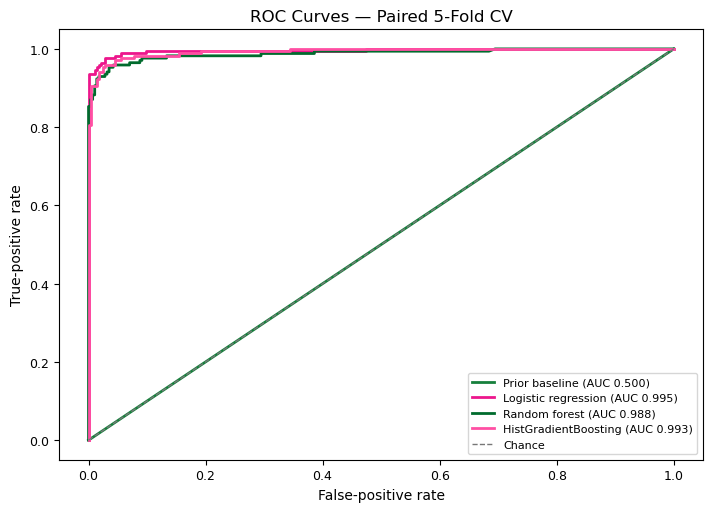

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 5.2))
for (name, probabilities), color in zip(cv_probabilities.items(), PALETTE):
    fpr, tpr, _ = roc_curve(y_train, probabilities)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {roc_auc_score(y_train, probabilities):.3f})")
ax.plot([0, 1], [0, 1], "--", color=GRAY, lw=1, label="Chance")
ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC Curves — Paired 5-Fold CV")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "01_roc_curves.png", dpi=220)
plt.show()

## 8. Precision–recall curves

Precision–recall views are especially useful when positive and negative class frequencies differ. The legend reports average precision (AP).

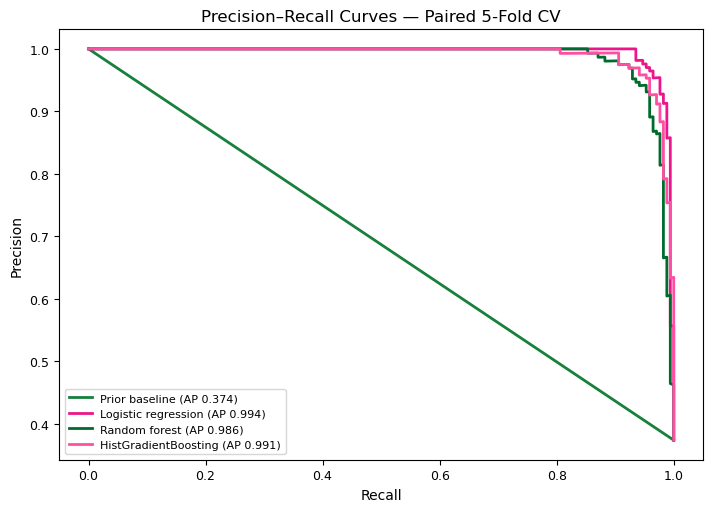

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 5.2))
for (name, probabilities), color in zip(cv_probabilities.items(), PALETTE):
    precision, recall, _ = precision_recall_curve(y_train, probabilities)
    ax.plot(recall, precision, color=color, lw=2, label=f"{name} (AP {average_precision_score(y_train, probabilities):.3f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–Recall Curves — Paired 5-Fold CV")
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "02_precision_recall.png", dpi=220)
plt.show()

## 9. Calibration curves

A well-calibrated model's predicted probabilities should agree with observed positive rates. The dashed diagonal represents ideal calibration. Small bins can be noisy, so interpret the plot alongside Brier score and ECE.

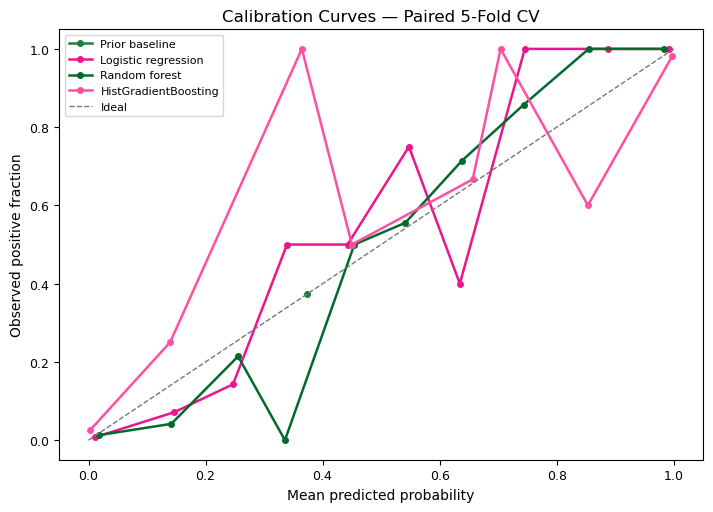

In [9]:
fig, ax = plt.subplots(figsize=(7.2, 5.2))
for (name, probabilities), color in zip(cv_probabilities.items(), PALETTE):
    observed, mean_predicted = calibration_curve(y_train, probabilities, n_bins=10, strategy="uniform")
    ax.plot(mean_predicted, observed, marker="o", ms=4, color=color, lw=1.8, label=name)
ax.plot([0, 1], [0, 1], "--", color=GRAY, lw=1, label="Ideal")
ax.set(xlabel="Mean predicted probability", ylabel="Observed positive fraction", title="Calibration Curves — Paired 5-Fold CV")
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "03_calibration_curves.png", dpi=220)
plt.show()

## 10. Compare discrimination and calibration metrics

Higher ROC-AUC/AP is generally better; lower Brier/ECE is generally better. The four panels use different metric scales, so compare models within each panel rather than comparing bar heights across panels.

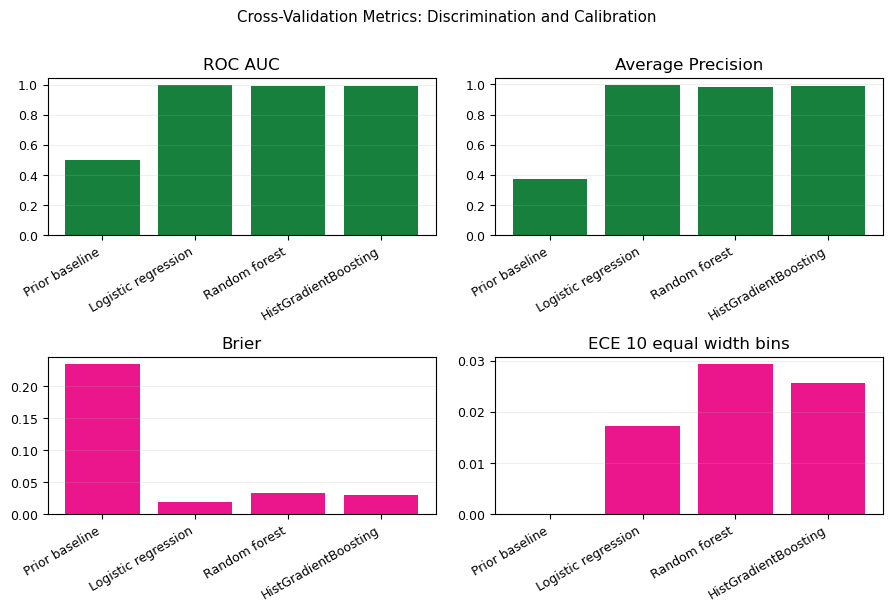

In [10]:
metric_columns = ["ROC_AUC", "Average_Precision", "Brier", "ECE_10_equal_width_bins"]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, column in zip(axes.flat, metric_columns):
    values = cv_table[column]
    bar_colors = [PINK if ("Brier" in column or "ECE" in column) else GREEN] * len(values)
    ax.bar(range(len(values)), values.values, color=bar_colors)
    ax.set_xticks(range(len(values)))
    ax.set_xticklabels(values.index, rotation=30, ha="right")
    ax.set_title(column.replace("_", " "))
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Cross-Validation Metrics: Discrimination and Calibration", y=1.01)
fig.tight_layout()
fig.savefig(ROOT / "figures" / "04_metric_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

## 11. Paired bootstrap uncertainty for AP improvement

This bootstrap resamples training OOF cases and estimates the AP difference between logistic regression and the prior baseline. The interval describes case-resampling uncertainty conditional on these OOF predictions; it is not a full refit/bootstrap of the entire training procedure.

In [11]:
def paired_bootstrap_ap(y_true, p_a, p_b, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    p_a, p_b = np.asarray(p_a), np.asarray(p_b)
    differences = []
    for _ in range(n_boot):
        indices = rng.integers(0, len(y_true), len(y_true))
        if np.unique(y_true[indices]).size == 2:
            differences.append(average_precision_score(y_true[indices], p_a[indices]) - average_precision_score(y_true[indices], p_b[indices]))
    return {
        "comparison": "Logistic regression minus Prior baseline (training OOF AP)",
        "difference": average_precision_score(y_true, p_a) - average_precision_score(y_true, p_b),
        "ci_low": float(np.quantile(differences, 0.025)),
        "ci_high": float(np.quantile(differences, 0.975)),
        "valid_bootstrap_replicates": len(differences),
        "requested_replicates": n_boot,
    }

bootstrap_result = pd.DataFrame([paired_bootstrap_ap(y_train, cv_probabilities["Logistic regression"], cv_probabilities["Prior baseline"])])
bootstrap_result.to_csv(ROOT / "results" / "paired_bootstrap_interval.csv", index=False)
display(bootstrap_result.round(4))

,comparison,difference,ci_low,ci_high,valid_bootstrap_replicates,requested_replicates
0,Logistic regression minus Prior baseline (trai...,0.6207,0.5774,0.6654,1000,1000


## 12. Threshold, cost, and review-capacity sensitivity

The grid tests hypothetical false-negative to false-positive cost ratios and review-capacity limits. It does **not** select a real-world threshold: that requires stakeholder-approved costs, operational capacity, external validation, and domain review.

In [12]:
thresholds = np.linspace(0.05, 0.95, 91)
sensitivity_rows = []
for model_name, probabilities in cv_probabilities.items():
    for fn_fp_ratio in [1, 2, 5, 10]:
        for capacity in [0.10, 0.20, 0.30, 0.50]:
            for threshold in thresholds:
                predictions = (probabilities >= threshold).astype(int)
                tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()
                sensitivity_rows.append({
                    "model": model_name,
                    "FN_cost_to_FP_cost_ratio": fn_fp_ratio,
                    "review_capacity_fraction": capacity,
                    "threshold": threshold,
                    "review_fraction": float(predictions.mean()),
                    "FP": int(fp), "FN": int(fn),
                    "cost_per_case": float((fp + fn_fp_ratio * fn) / len(y_train)),
                    "within_capacity": bool(predictions.mean() <= capacity),
                })
sensitivity_grid = pd.DataFrame(sensitivity_rows)
sensitivity_grid.to_csv(ROOT / "results" / "threshold_sensitivity_grid.csv", index=False)
print("Sensitivity grid rows:", len(sensitivity_grid))
display(sensitivity_grid.head())

Sensitivity grid rows: 5824


,model,FN_cost_to_FP_cost_ratio,review_capacity_fraction,threshold,review_fraction,FP,FN,cost_per_case,within_capacity
0,Prior baseline,1,0.1,0.05,1.0,285,0,0.626374,False
1,Prior baseline,1,0.1,0.06,1.0,285,0,0.626374,False
2,Prior baseline,1,0.1,0.07,1.0,285,0,0.626374,False
3,Prior baseline,1,0.1,0.08,1.0,285,0,0.626374,False
4,Prior baseline,1,0.1,0.09,1.0,285,0,0.626374,False


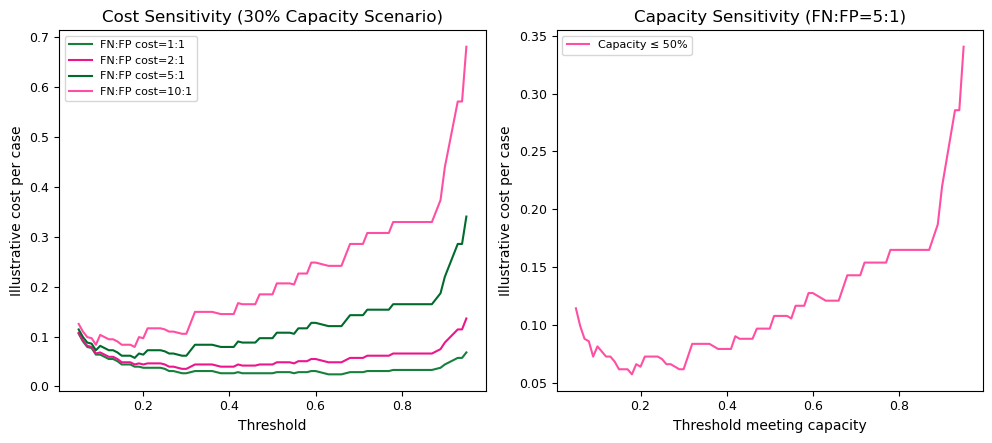

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ratio, color in zip([1, 2, 5, 10], PALETTE):
    subset = sensitivity_grid[(sensitivity_grid.model == "Logistic regression") & (sensitivity_grid.FN_cost_to_FP_cost_ratio == ratio) & (sensitivity_grid.review_capacity_fraction == 0.30)]
    axes[0].plot(subset.threshold, subset.cost_per_case, color=color, label=f"FN:FP cost={ratio}:1")
axes[0].set(xlabel="Threshold", ylabel="Illustrative cost per case", title="Cost Sensitivity (30% Capacity Scenario)")
axes[0].legend()
for capacity, color in zip([0.10, 0.20, 0.30, 0.50], PALETTE):
    subset = sensitivity_grid[(sensitivity_grid.model == "Logistic regression") & (sensitivity_grid.FN_cost_to_FP_cost_ratio == 5) & (sensitivity_grid.review_capacity_fraction == capacity)]
    eligible = subset[subset.within_capacity]
    if len(eligible):
        axes[1].plot(eligible.threshold, eligible.cost_per_case, color=color, label=f"Capacity ≤ {capacity:.0%}")
axes[1].set(xlabel="Threshold meeting capacity", ylabel="Illustrative cost per case", title="Capacity Sensitivity (FN:FP=5:1)")
axes[1].legend()
fig.tight_layout()
fig.savefig(ROOT / "figures" / "05_threshold_sensitivity.png", dpi=220)
plt.show()

## 13. Critical-slice analysis: mean radius quartiles

Quartile cut points are derived from the training data, then applied to the held-out test set. This is an exploratory subgroup check: small groups can have unstable metrics and should not be treated as a causal or clinical finding.

In [14]:
radius_column = "mean radius"
quartile_edges = np.unique(np.quantile(X_train[radius_column], [0, 0.25, 0.50, 0.75, 1.0]))
test_slices = pd.cut(X_test[radius_column].reset_index(drop=True), bins=quartile_edges, include_lowest=True, duplicates="drop")
logistic_test_p = test_probabilities["Logistic regression"]
y_test_reset = y_test.reset_index(drop=True)
slice_rows = []
for label in test_slices.cat.categories:
    indices = np.where(test_slices.astype(str).to_numpy() == str(label))[0]
    if len(indices) == 0:
        continue
    yy = y_test_reset.iloc[indices].to_numpy()
    pp = logistic_test_p[indices]
    pred = (pp >= 0.50).astype(int)
    slice_rows.append({
        "feature": radius_column, "slice": str(label), "n": len(indices),
        "positive_rate": float(yy.mean()),
        "ROC_AUC": float(roc_auc_score(yy, pp)) if len(np.unique(yy)) == 2 else np.nan,
        "Brier": float(brier_score_loss(yy, pp)),
        "Recall_at_0.5": float(recall_score(yy, pred, zero_division=0)),
        "FP": int(((pred == 1) & (yy == 0)).sum()),
        "FN": int(((pred == 0) & (yy == 1)).sum()),
    })
slice_table = pd.DataFrame(slice_rows)
slice_table.to_csv(ROOT / "results" / "illustrative_feature_slice_analysis.csv", index=False)
display(slice_table.round(3))

,feature,slice,n,positive_rate,ROC_AUC,Brier,Recall_at_0.5,FP,FN
0,mean radius,"(6.9799999999999995, 11.71]",30,0.000,NaN,0.002,0.000,0,0
1,mean radius,"(11.71, 13.34]",26,0.077,1.000,0.003,1.000,0,0
2,mean radius,"(13.34, 15.935]",31,0.452,0.966,0.073,0.786,1,3
3,mean radius,"(15.935, 28.11]",27,0.963,1.000,0.001,1.000,0,0


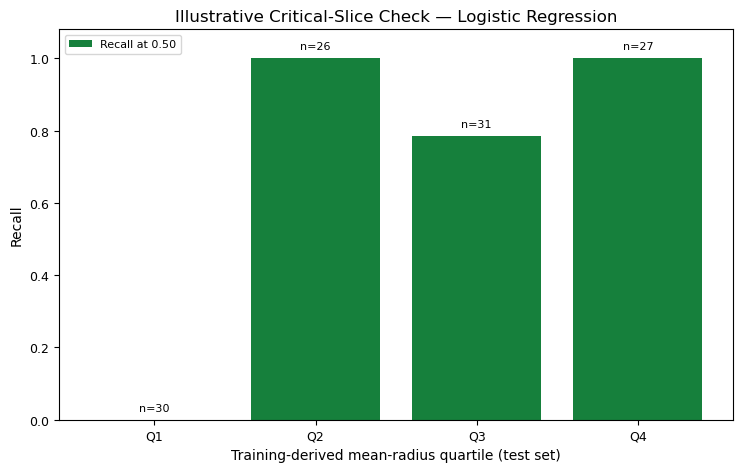

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
positions = np.arange(len(slice_table))
ax.bar(positions, slice_table["Recall_at_0.5"], color=GREEN, label="Recall at 0.50")
ax.set_xticks(positions)
ax.set_xticklabels([f"Q{i+1}" for i in range(len(slice_table))])
ax.set_ylim(0, 1.08)
ax.set(xlabel="Training-derived mean-radius quartile (test set)", ylabel="Recall", title="Illustrative Critical-Slice Check — Logistic Regression")
for i, row in slice_table.reset_index(drop=True).iterrows():
    ax.text(i, min(row["Recall_at_0.5"] + 0.025, 1.03), f"n={int(row['n'])}", ha="center", fontsize=8)
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "figures" / "06_critical_slice.png", dpi=220)
plt.show()

## 14. Save paired predictions and environment metadata

These files support reproducibility and later inspection. The report should quote only values produced by the run, explain limitations, and distinguish model metrics from a deployment decision.

In [16]:
cv_predictions = pd.DataFrame({"y_true_train_oof": y_train.to_numpy()})
for name, probabilities in cv_probabilities.items():
    cv_predictions["cv_p_" + name] = probabilities
cv_predictions.to_csv(ROOT / "results" / "paired_cv_predictions.csv", index=False)

test_predictions = pd.DataFrame({"y_true": y_test.to_numpy()})
for name, probabilities in test_probabilities.items():
    test_predictions["p_" + name] = probabilities
test_predictions.to_csv(ROOT / "results" / "paired_test_predictions.csv", index=False)

provenance = f"""# Frozen dataset provenance

- Dataset: Wisconsin Diagnostic Breast Cancer, distributed by scikit-learn's `load_breast_cancer`.
- Local frozen CSV: `wdbc_sklearn_frozen.csv`
- Rows: {len(df)}
- Predictors: {X.shape[1]} numeric features; target: `diagnosis` (benign/malignant)
- Local CSV SHA-256: `{sha256}`
- Source page: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
- Upstream dataset: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- The hash verifies the local file bytes only. Verify current source/license terms before redistribution.
- Educational benchmark only; not a clinical decision tool.
"""
(ROOT / "data" / "DATA_PROVENANCE.md").write_text(provenance, encoding="utf-8")
environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    "seed": SEED, "test_size": TEST_SIZE, "cv_folds": N_SPLITS,
    "dataset_csv": "data/wdbc_sklearn_frozen.csv", "dataset_sha256": sha256,
    "positive_class": POSITIVE_LABEL, "positive_class_encoding": "1=malignant; 0=benign",
    "threshold_cost_scenarios": "illustrative sensitivity grid only; not a final decision",
}
(ROOT / "results" / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
print("Saved paired predictions, provenance, and environment metadata.")
print("CV comparison:")
display(cv_table.round(4))
print("Held-out test comparison:")
display(test_table.round(4))
print("Bootstrap interval:")
display(bootstrap_result.round(4))
print("Critical slices:")
display(slice_table.round(3))
print("Figures saved to:", (ROOT / "figures").resolve())
print("Results saved to:", (ROOT / "results").resolve())

Saved paired predictions, provenance, and environment metadata.
CV comparison:


,ROC_AUC,Average_Precision,Brier,ECE_10_equal_width_bins,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5
Model,,,,,,,,
Prior baseline,0.5000,0.3736,0.2340,0.0000,0.6264,0.0000,0.0000,0.0000
Logistic regression,0.9953,0.9943,0.0191,0.0173,0.9736,0.9759,0.9529,0.9643
Random forest,0.9879,0.9862,0.0333,0.0293,0.9582,0.9521,0.9353,0.9436
HistGradientBoosting,0.9933,0.9907,0.0295,0.0257,0.9648,0.9639,0.9412,0.9524


Held-out test comparison:


,ROC_AUC,Average_Precision,Brier,ECE_10_equal_width_bins,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5
Model,,,,,,,,
Prior baseline,0.5000,0.3684,0.2327,0.0052,0.6316,0.000,0.0000,0.0000
Logistic regression,0.9960,0.9943,0.0213,0.0302,0.9649,0.975,0.9286,0.9512
Random forest,0.9954,0.9929,0.0308,0.0521,0.9737,1.000,0.9286,0.9630
HistGradientBoosting,0.9914,0.9905,0.0254,0.0289,0.9737,1.000,0.9286,0.9630


Bootstrap interval:


,comparison,difference,ci_low,ci_high,valid_bootstrap_replicates,requested_replicates
0,Logistic regression minus Prior baseline (trai...,0.6207,0.5774,0.6654,1000,1000


Critical slices:


,feature,slice,n,positive_rate,ROC_AUC,Brier,Recall_at_0.5,FP,FN
0,mean radius,"(6.9799999999999995, 11.71]",30,0.000,NaN,0.002,0.000,0,0
1,mean radius,"(11.71, 13.34]",26,0.077,1.000,0.003,1.000,0,0
2,mean radius,"(13.34, 15.935]",31,0.452,0.966,0.073,0.786,1,3
3,mean radius,"(15.935, 28.11]",27,0.963,1.000,0.001,1.000,0,0


Figures saved to: C:\Users\allde\Downloads\DS_A4_Model_Comparison_and_Calibration_Package_Fixed\DS_A4_Model_Comparison_and_Calibration\figures
Results saved to: C:\Users\allde\Downloads\DS_A4_Model_Comparison_and_Calibration_Package_Fixed\DS_A4_Model_Comparison_and_Calibration\results


## 15. Interpretation checklist and limits

- Compare models using the same split and folds; do not select solely from one metric.
- ROC-AUC/AP assess ranking; Brier/ECE assess probability calibration; threshold metrics depend on the chosen threshold.
- A better average score does not guarantee better performance in every subgroup or operational setting.
- Threshold scenarios depend on assumed costs and capacity. Obtain stakeholder agreement and evaluate impact before any real use.
- This dataset is small and educational. Results do not establish clinical validity, causality, fairness, or deployment readiness.
- Record your own interpretation, limitations, AI-use disclosure, and any deviations from the protocol before submission.